In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [2]:
with open("exercise_text.json", "r", encoding="utf-8") as f:
    data = json.load(f)

text = data["text"]

print("Number of characters:", len(text))
print("Number of words     :", len(text.split()))
print("\nOriginal text:\n")
print(text)

Number of characters: 840
Number of words     : 123

Original text:

In this exercise, you are required to Apply and evaluate CNN, ANN, and RNN models Compare their performance and identify the model that achieves the highest accuracy for image classification using the **Iris Flowers dataset**. You will load and preprocess image data, design a multi-layer CNN architecture using TensorFlow/Keras, and train the model to recognize different object categories. After training, you will evaluate the model's performance on unseen test data and visualize the training loss across epochs. The objective of this exercise is to provide hands-on experience with **Deep Learning and Computer Vision**, enabling you to understand the complete workflow of an image classification project. Also solve the Large Language Models (LLMs) Architecture & Work. And Using LLMs with LangChain, passing prompts programmatically.


In [3]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(r"C:\Users\GCA\bert_tokenizer", local_files_only=True)
print("Tokenizer loaded:", tokenizer.__class__.__name__)

Tokenizer loaded: BertTokenizer


In [5]:
tokens = tokenizer.tokenize(text)
print("Total tokens:", len(tokens))
print("\nFirst 40 tokens:\n", tokens[:40])

token_ids = tokenizer.convert_tokens_to_ids(tokens)
print("\nFirst 40 token IDs:\n", token_ids[:40])

encoded = tokenizer(text, return_tensors="pt" if False else None,
                    truncation=True, max_length=512)

print("\nEncoded keys:", list(encoded.keys()))
print("input_ids length   :", len(encoded["input_ids"]))
print("First 20 input_ids :", encoded["input_ids"][:20])
print("Attention mask     :", encoded["attention_mask"][:20], "...")

Total tokens: 173

First 40 tokens:
 ['in', 'this', 'exercise', ',', 'you', 'are', 'required', 'to', 'apply', 'and', 'evaluate', 'cnn', ',', 'ann', ',', 'and', 'rn', '##n', 'models', 'compare', 'their', 'performance', 'and', 'identify', 'the', 'model', 'that', 'achieve', '##s', 'the', 'highest', 'accuracy', 'for', 'image', 'classification', 'using', 'the', '*', '*', 'iris']

First 40 token IDs:
 [1999, 2023, 6912, 1010, 2017, 2024, 3223, 2000, 6611, 1998, 16157, 13229, 1010, 5754, 1010, 1998, 29300, 2078, 4275, 12826, 2037, 2836, 1998, 6709, 1996, 2944, 2008, 6162, 2015, 1996, 3284, 10640, 2005, 3746, 5579, 2478, 1996, 1008, 1008, 11173]

Encoded keys: ['input_ids', 'token_type_ids', 'attention_mask']
input_ids length   : 175
First 20 input_ids : [101, 1999, 2023, 6912, 1010, 2017, 2024, 3223, 2000, 6611, 1998, 16157, 13229, 1010, 5754, 1010, 1998, 29300, 2078, 4275]
Attention mask     : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] ...


In [6]:
token_table = pd.DataFrame({
    "Position": range(len(tokens)),
    "Token": tokens,
    "Token ID": token_ids
})
display(token_table.head(30))

,Position,Token,Token ID
0,0,in,1999
1,1,this,2023
2,2,exercise,6912
3,3,",",1010
4,4,you,2017
5,5,are,2024
6,6,required,3223
7,7,to,2000
8,8,apply,6611
9,9,and,1998


In [7]:
decoded = tokenizer.decode(encoded["input_ids"], skip_special_tokens=True)
print("Decoded text:\n")
print(decoded)

Decoded text:

in this exercise, you are required to apply and evaluate cnn, ann, and rnn models compare their performance and identify the model that achieves the highest accuracy for image classification using the * * iris flowers dataset * *. you will load and preprocess image data, design a multi - layer cnn architecture using tensorflow / keras, and train the model to recognize different object categories. after training, you will evaluate the model ' s performance on unseen test data and visualize the training loss across epochs. the objective of this exercise is to provide hands - on experience with * * deep learning and computer vision * *, enabling you to understand the complete workflow of an image classification project. also solve the large language models ( llms ) architecture & work. and using llms with langchain, passing prompts programmatically.


In [8]:
words = text.split()[:12]
for w in words:
    print(f"{w:15s} -> {tokenizer.tokenize(w)}")

In              -> ['in']
this            -> ['this']
exercise,       -> ['exercise', ',']
you             -> ['you']
are             -> ['are']
required        -> ['required']
to              -> ['to']
Apply           -> ['apply']
and             -> ['and']
evaluate        -> ['evaluate']
CNN,            -> ['cnn', ',']
ANN,            -> ['ann', ',']


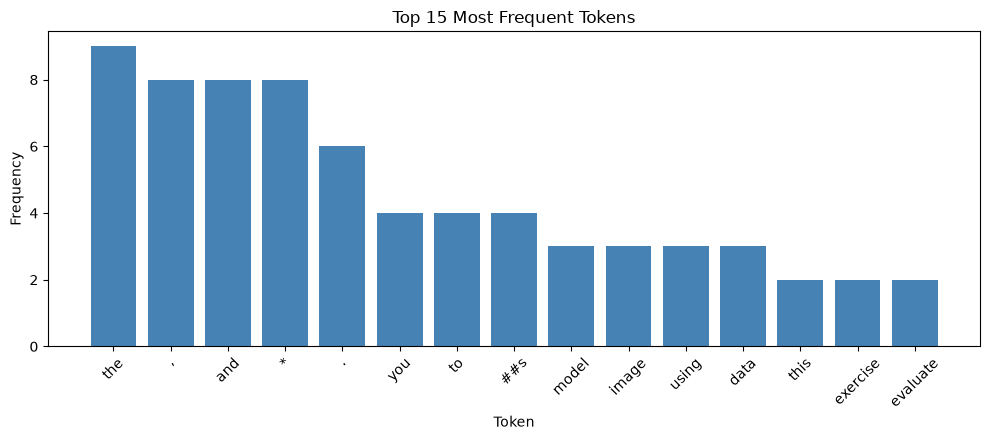

In [9]:
from collections import Counter

freq = Counter(tokens).most_common(15)
labels, counts = zip(*freq)

plt.figure(figsize=(10, 4.5))
plt.bar(labels, counts, color="steelblue")
plt.title("Top 15 Most Frequent Tokens")
plt.xlabel("Token"); plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()